# 09 — Dataset overview: the selected features and the BCM, per segment

Loads the model datasets in `results/datasets/` (one file per segment, made by `scripts/extract_features.py`) and shows,
for every segment, the BCM charge and each selected feature along the segment.

- **valid** shots only (not frozen laser / camera, not the last row of a segment); invalid shots are counted in the table
- dots = every valid shot, line = 51-shot rolling mean
- panel titles: correlation of the feature with BCM_GUN over the valid shots of the segment

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# repo root = first folder up from here that contains results/datasets (works from notebooks/ and notebooks/anto/)
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results" / "datasets").is_dir())
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "dataset_overview"
OUT.mkdir(parents=True, exist_ok=True)

ROLL = 51
BCM_COLOR, FEATURE_COLOR, INK, GRID = "#2b2b29", "#2a78d6", "#2b2b29", "#e6e5e1"

manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]
TARGET = manifest["target"]
print(f"target: {TARGET}")
print(f"{len(FEATURES)} features: {FEATURES}")

target: BCM_GUN
10 features: ['lab_laser_power', 'PGLA_drop', 'SVD_s1', 'BTV_intensity', 'SVD_s5', 'SVD_s6', 'SVD_s4', 'PKI15A', 'BTV_tilt', 'BTV_mean_x']


## Load every segment

In [2]:
segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    segments[info["segment"]] = {
        "run": info["run"], "chunks": f"{info['first_chunk']}–{info['last_chunk']}",
        "X": pd.DataFrame(z["X"], columns=list(z["features"])), "y": z["y"], "valid": z["valid"],
        "laser_frozen": z["laser_frozen"], "btv_frozen": z["btv_frozen"],
    }

overview = pd.DataFrame({
    k: {"run": s["run"].removeprefix("acquisition_"), "chunks": s["chunks"], "shots": len(s["y"]),
        "valid": int(s["valid"].sum()), "frozen laser": int(s["laser_frozen"].sum()), "frozen camera": int(s["btv_frozen"].sum()),
        "BCM mean [nC]": s["y"][s["valid"]].mean(), "BCM std [nC]": s["y"][s["valid"]].std(),
        "missing feature values": int(s["X"][s["valid"]].isna().sum().sum())}
    for k, s in segments.items()
}).T.rename_axis("segment")
overview.style.format({"BCM mean [nC]": "{:.3f}", "BCM std [nC]": "{:.3f}"})

,run,chunks,shots,valid,frozen laser,frozen camera,BCM mean [nC],BCM std [nC],missing feature values
segment,,,,,,,,,
0,2026-10-07_21-43-26,11–71,6027,4637,1386,3,0.223,0.027,448
1,2026-10-08_00-08-19,0–193,19400,16658,2642,116,4.814,0.417,1764
2,2026-10-08_15-42-27,0–1,200,154,45,1,0.145,0.013,0
3,2026-10-08_15-42-27,4–74,7100,5427,1670,2,0.122,0.023,399
4,2026-10-08_15-42-27,76–120,4500,3855,619,30,0.101,0.033,546
5,2026-10-08_21-11-47,0–199,20000,17443,2534,24,5.468,0.492,217
6,2026-10-09_07-46-07,0–40,4100,3137,961,1,5.504,0.269,0
7,2026-10-09_07-46-07,87–106,2000,1780,219,0,10.097,0.652,14


### Feature statistics per segment (valid shots): mean ± std

In [3]:
stats = pd.DataFrame({
    k: {f: f"{s['X'].loc[s['valid'], f].mean():.4g} ± {s['X'].loc[s['valid'], f].std():.2g}" for f in FEATURES}
    for k, s in segments.items()
}).rename_axis(index="feature", columns="segment")
stats

segment,0,1,2,3,4,5,6,7
feature,,,,,,,,
lab_laser_power,3.812e-06 ± 6.6e-08,1.008e-05 ± 4.8e-07,3.693e-06 ± 5.2e-08,3.664e-06 ± 6.2e-08,3.627e-06 ± 8e-08,1.105e-05 ± 5.3e-07,1.121e-05 ± 4.2e-07,1.852e-05 ± 1.2e-06
PGLA_drop,0.5499 ± 1.1,6.024 ± 1.2,0.1078 ± 1.1,0.1382 ± 1.1,0.1457 ± 1.1,6.581 ± 1.2,6.682 ± 1.1,12.05 ± 1.3
SVD_s1,3297 ± 4.1e+02,1.386e+04 ± 2e+03,5962 ± 5.3e+02,4762 ± 9.3e+02,3670 ± 1.4e+03,6661 ± 6.6e+02,6809 ± 3.7e+02,1.425e+04 ± 1.5e+03
BTV_intensity,8.995e+05 ± 2e+05,4.375e+06 ± 6.7e+05,1.626e+06 ± 1.6e+05,1.282e+06 ± 2.9e+05,9.876e+05 ± 4.9e+05,2.372e+06 ± 2.3e+05,2.428e+06 ± 1.5e+05,4.98e+06 ± 5.2e+05
SVD_s5,149.5 ± 23,334.2 ± 62,192.9 ± 29,174.5 ± 28,151.2 ± 35,135 ± 13,137.1 ± 13,249.5 ± 28
SVD_s6,90.58 ± 11,237 ± 38,117.6 ± 11,103.5 ± 15,93.93 ± 17,101.4 ± 10,103.2 ± 8.5,196 ± 26
SVD_s4,199.3 ± 32,603.6 ± 1.2e+02,308.5 ± 71,252.5 ± 54,211.9 ± 62,280.6 ± 36,287.2 ± 30,606.5 ± 88
PKI15A,131.6 ± 0.18,131.8 ± 1.3,132 ± 0.2,131.9 ± 0.33,131.2 ± 0.46,131.5 ± 10,131.9 ± 0.18,132 ± 0.19
BTV_tilt,61.29 ± 15,70.43 ± 16,62.56 ± 25,62.02 ± 14,54.96 ± 17,74.49 ± 13,76.06 ± 12,73.37 ± 16


## BCM and features along each segment

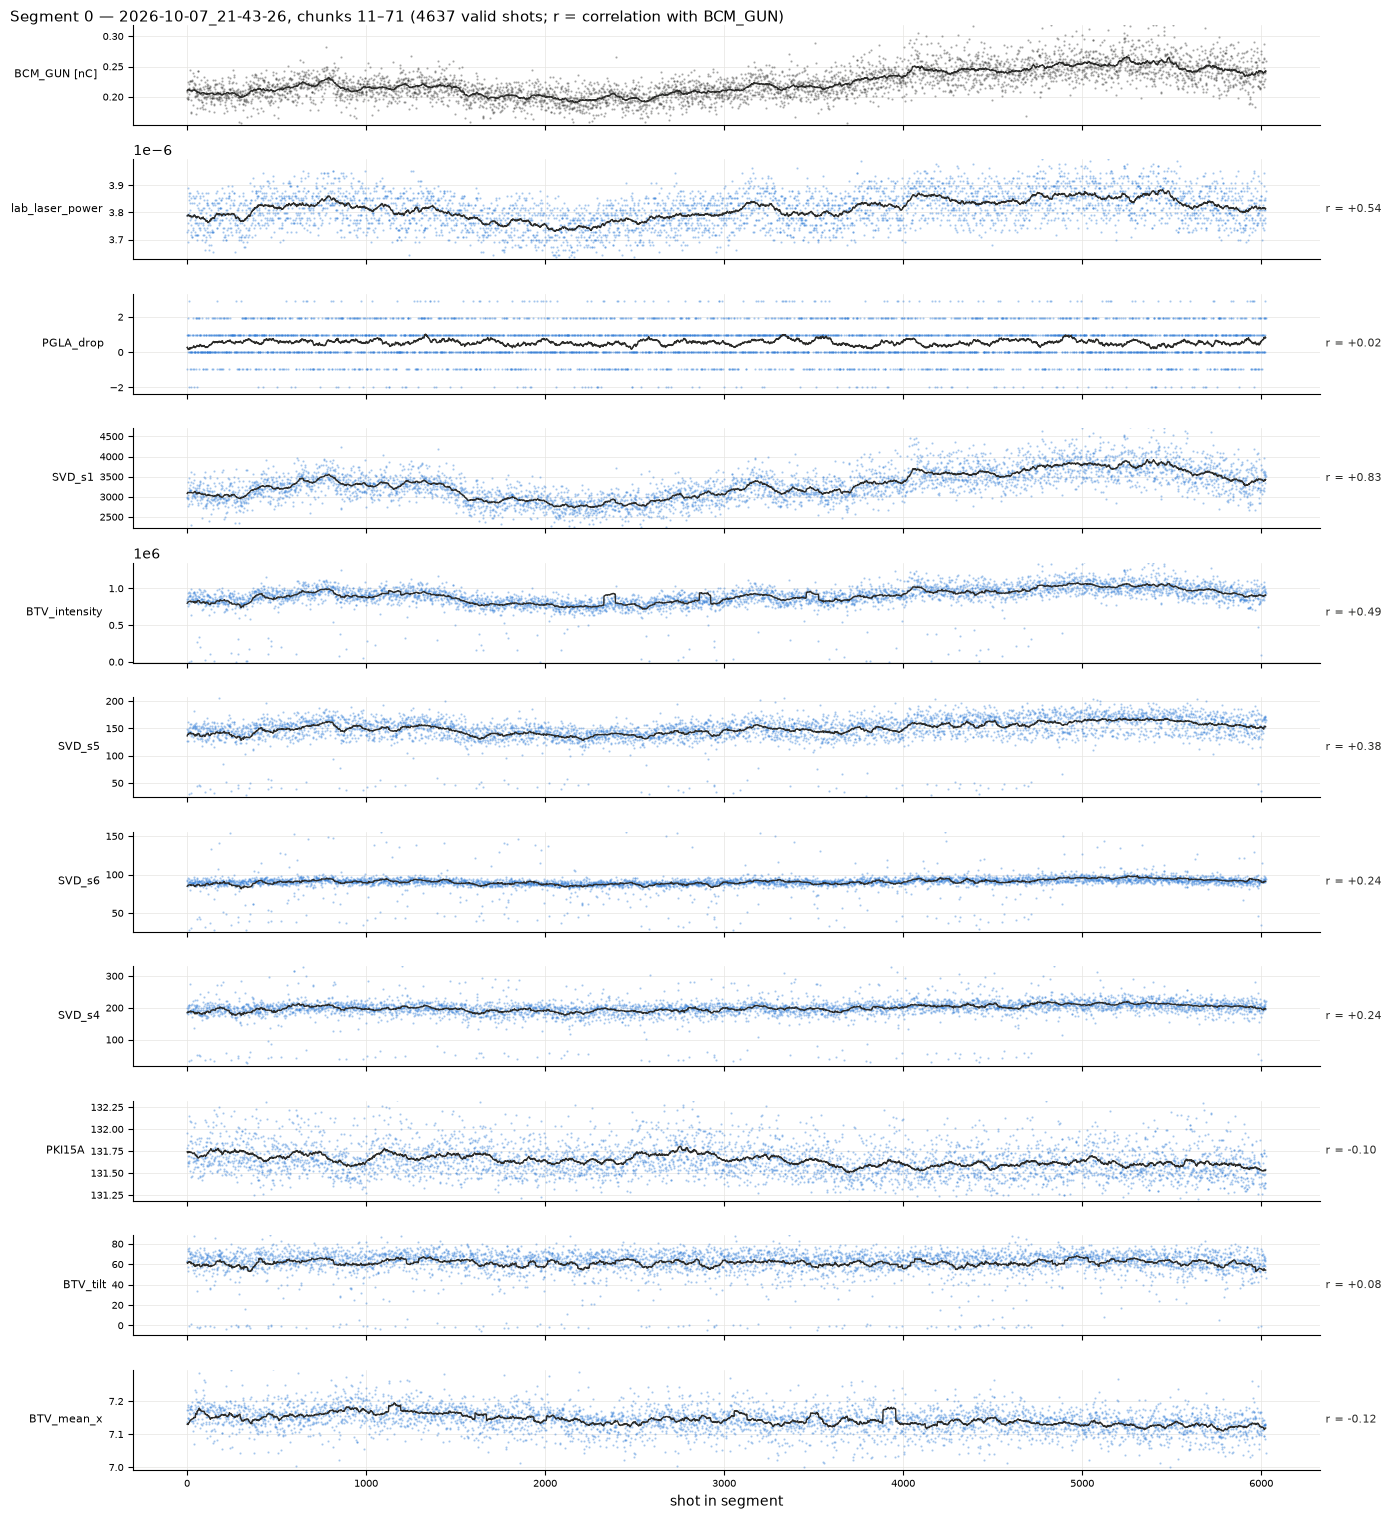

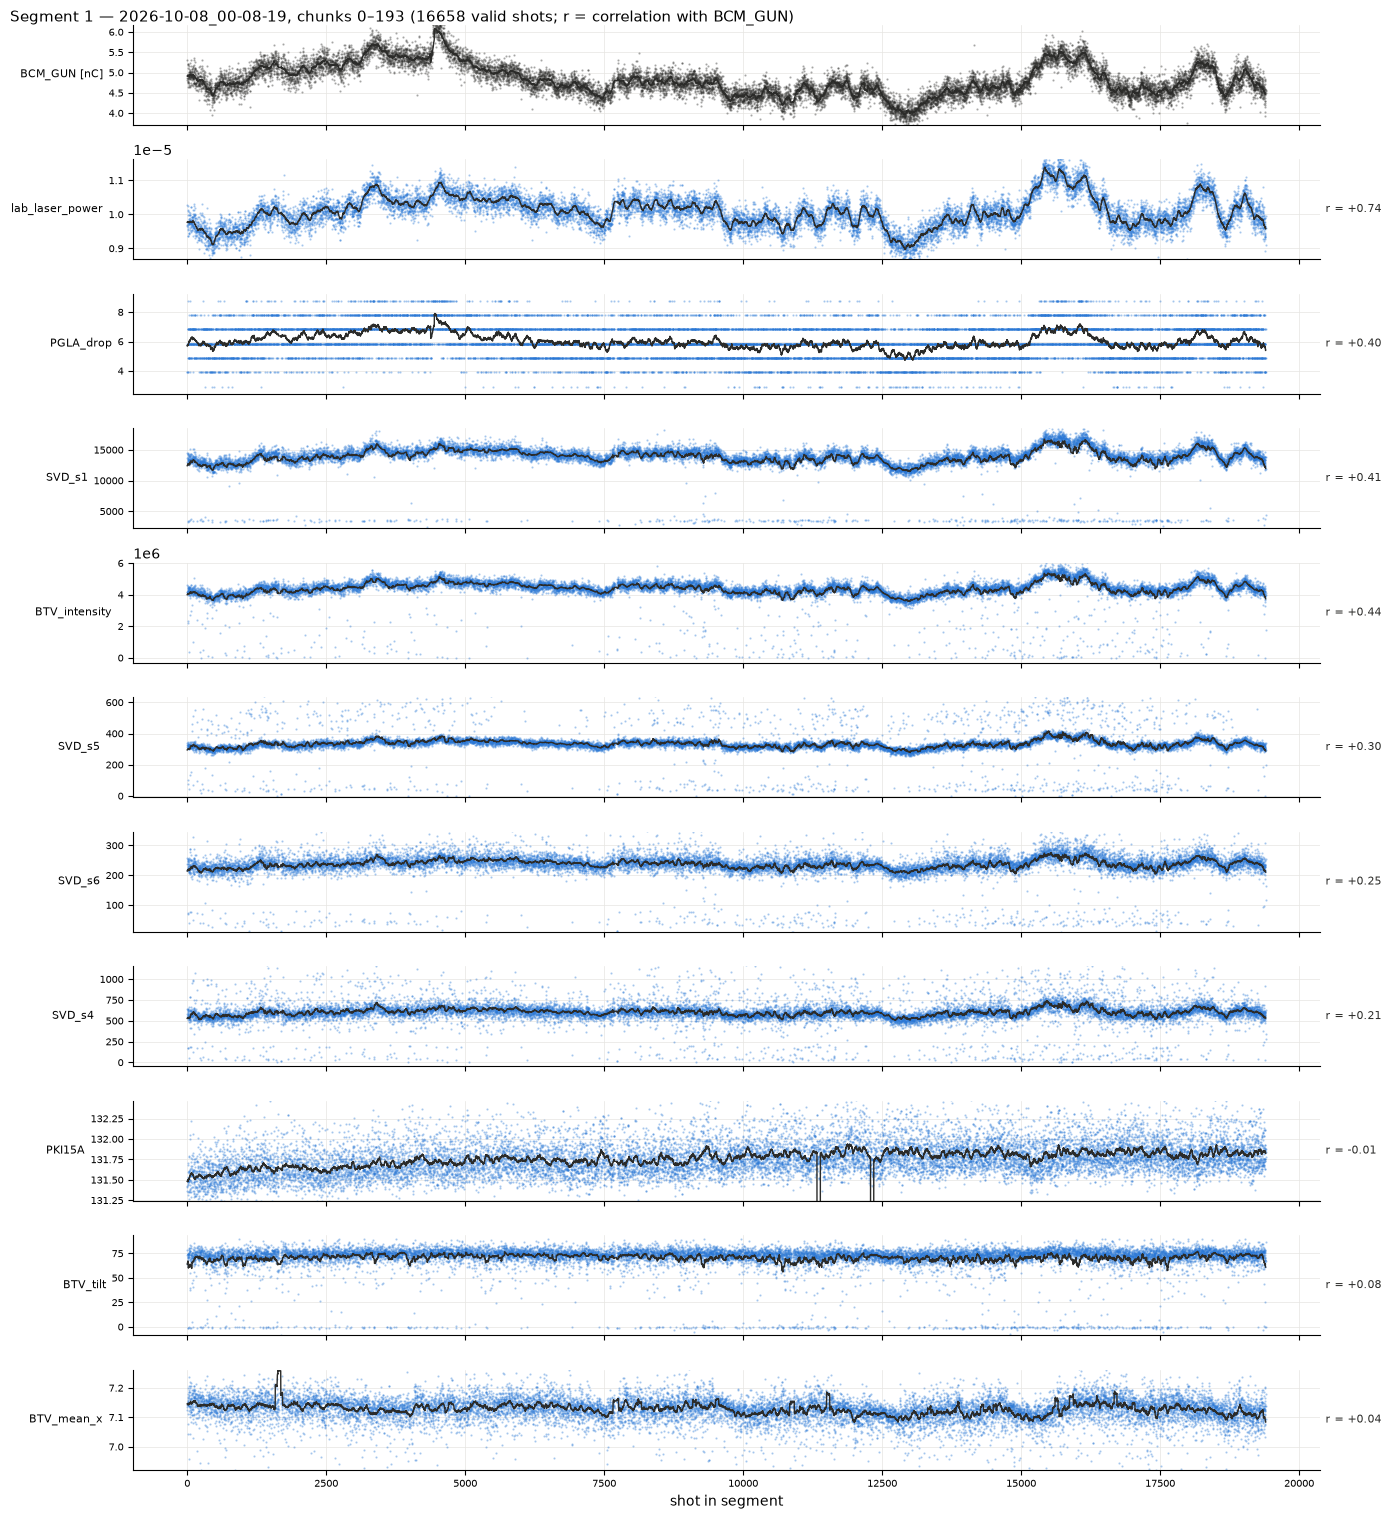

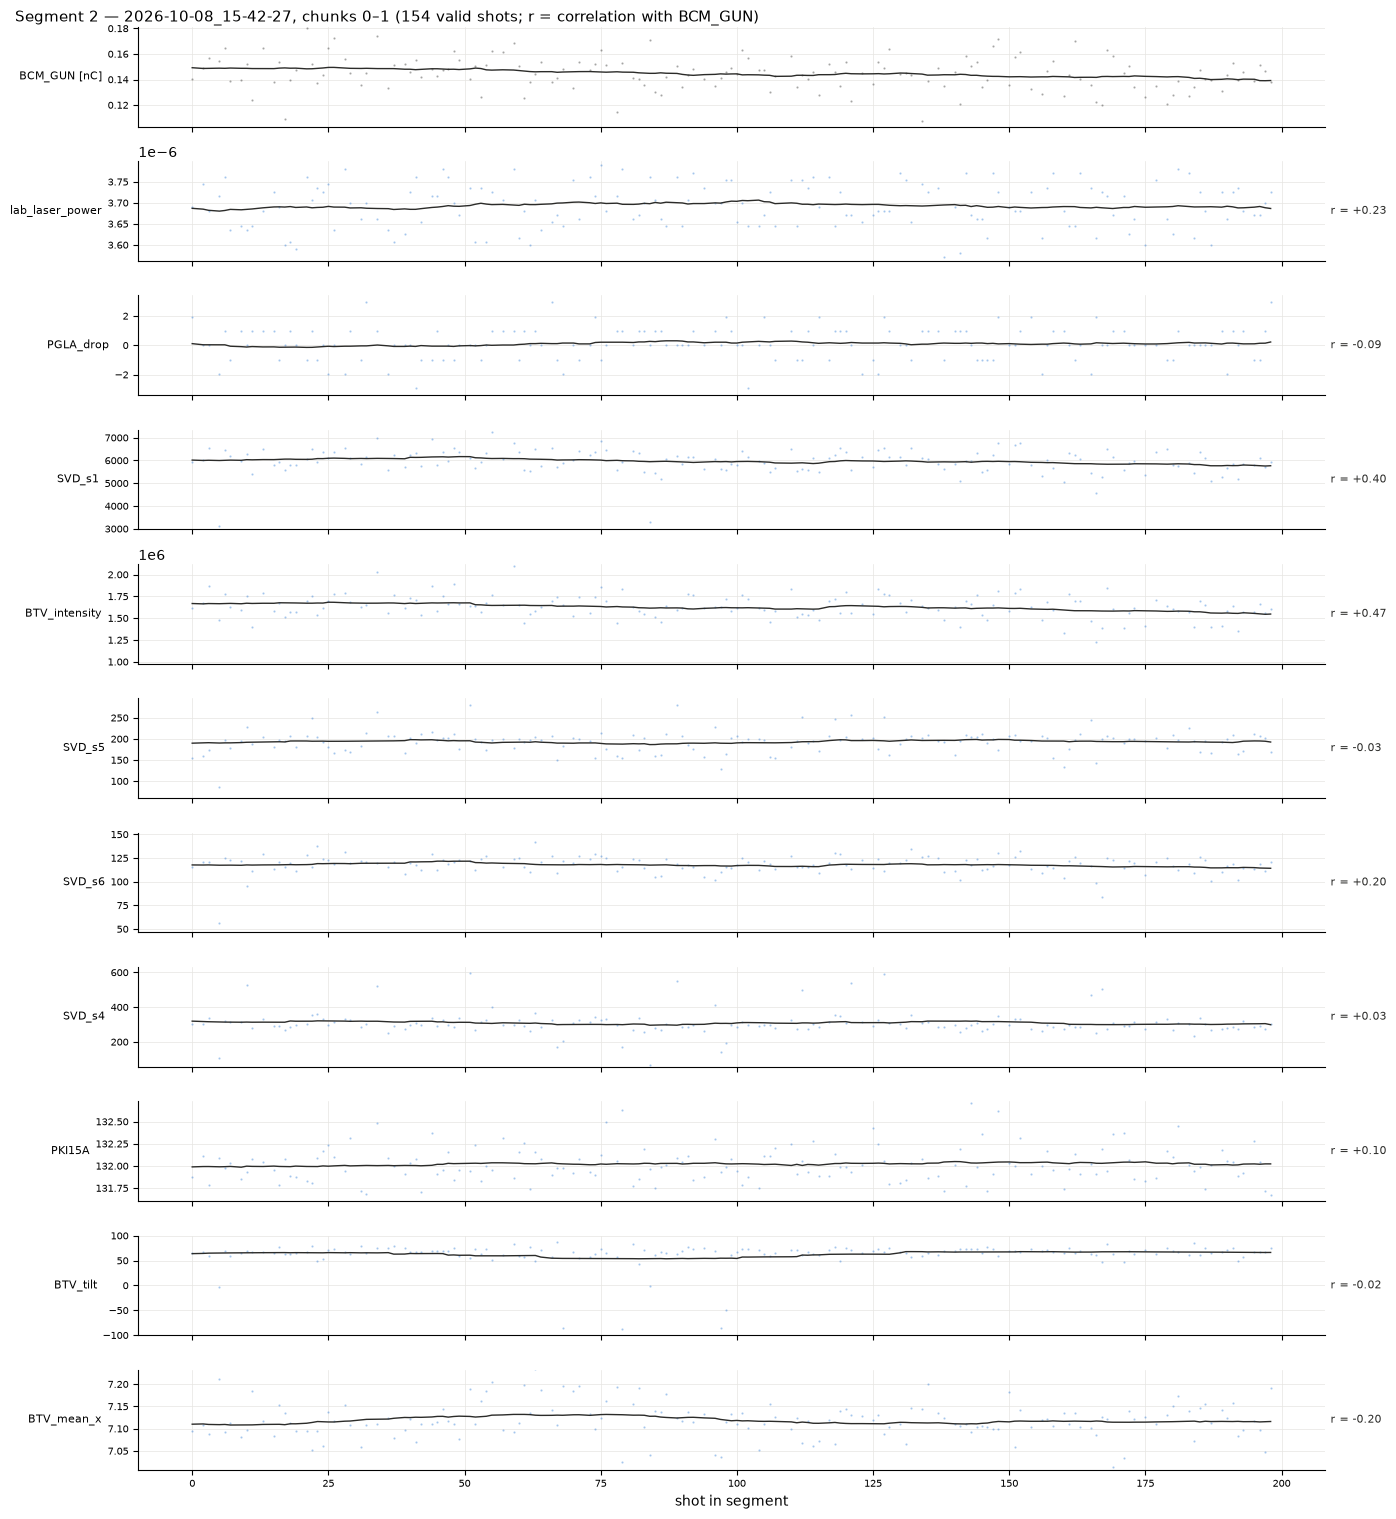

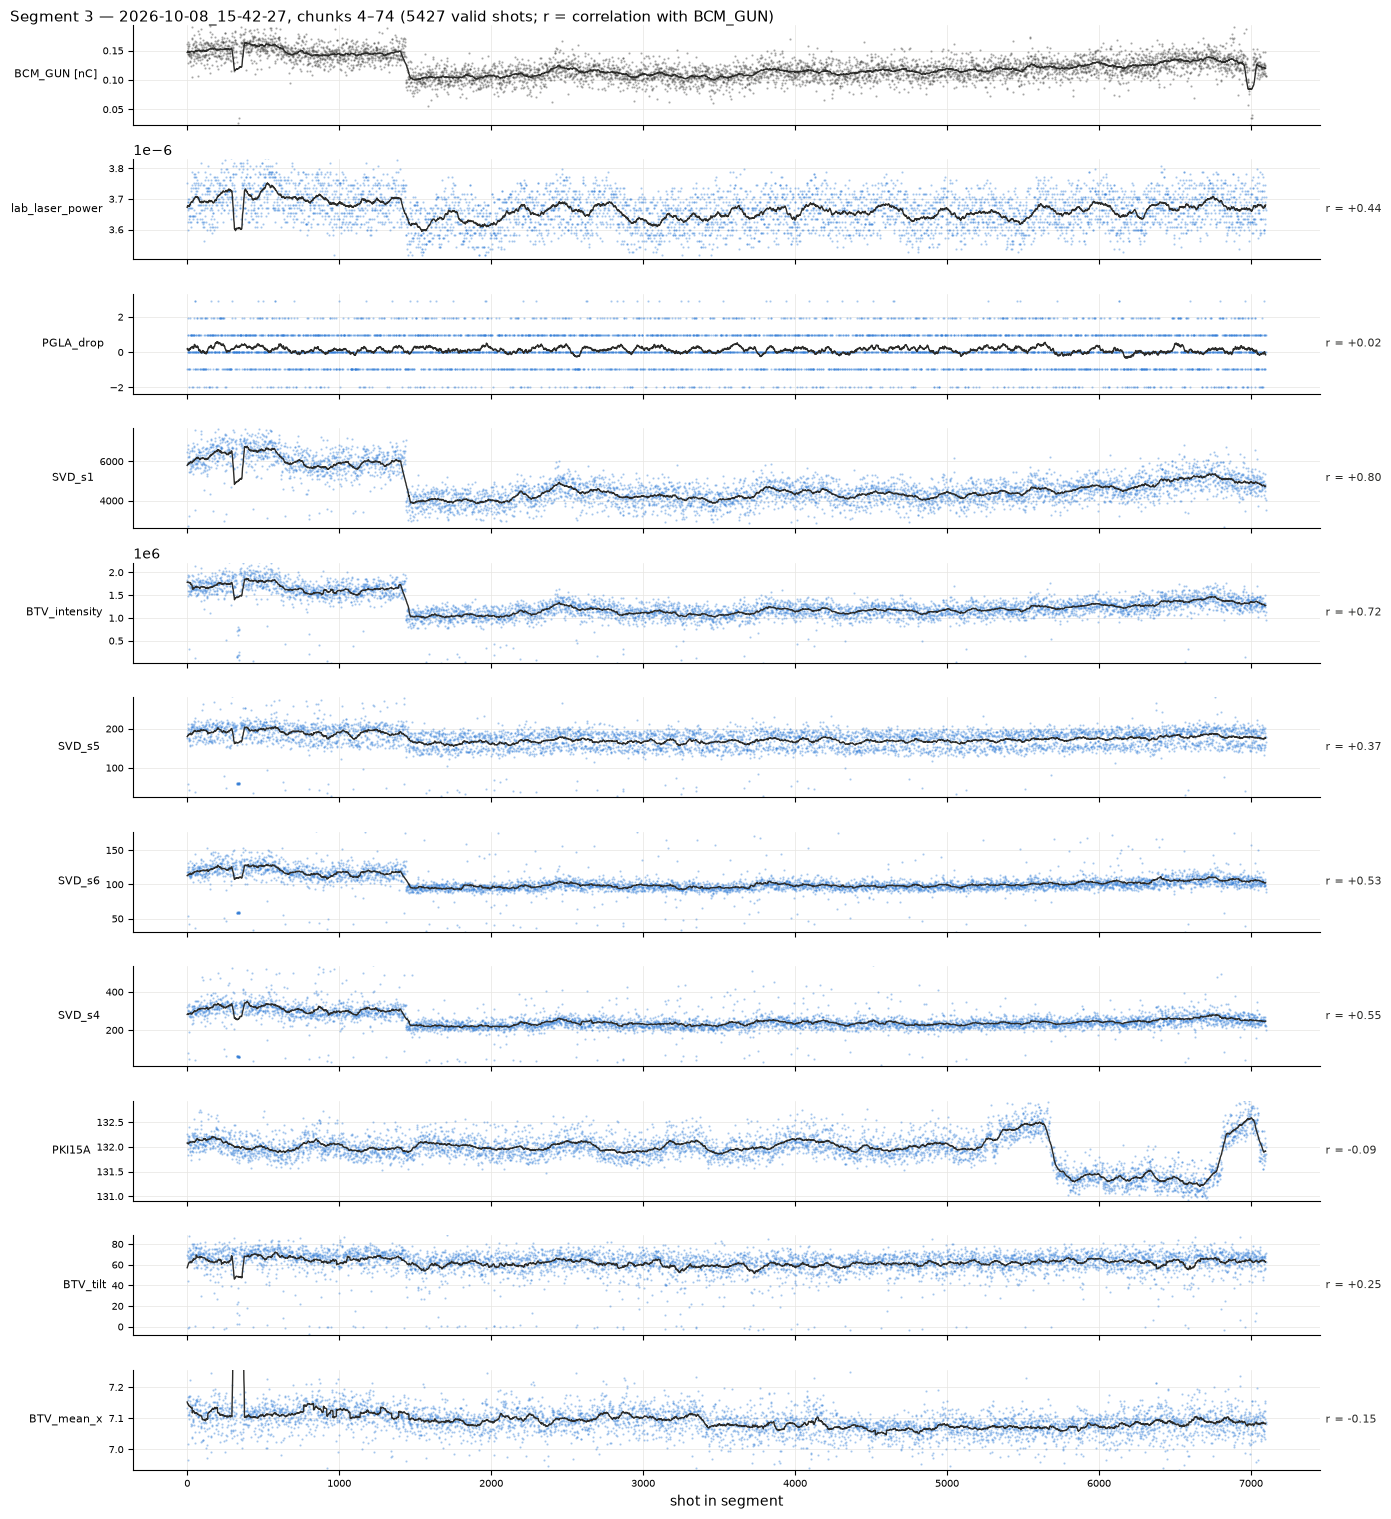

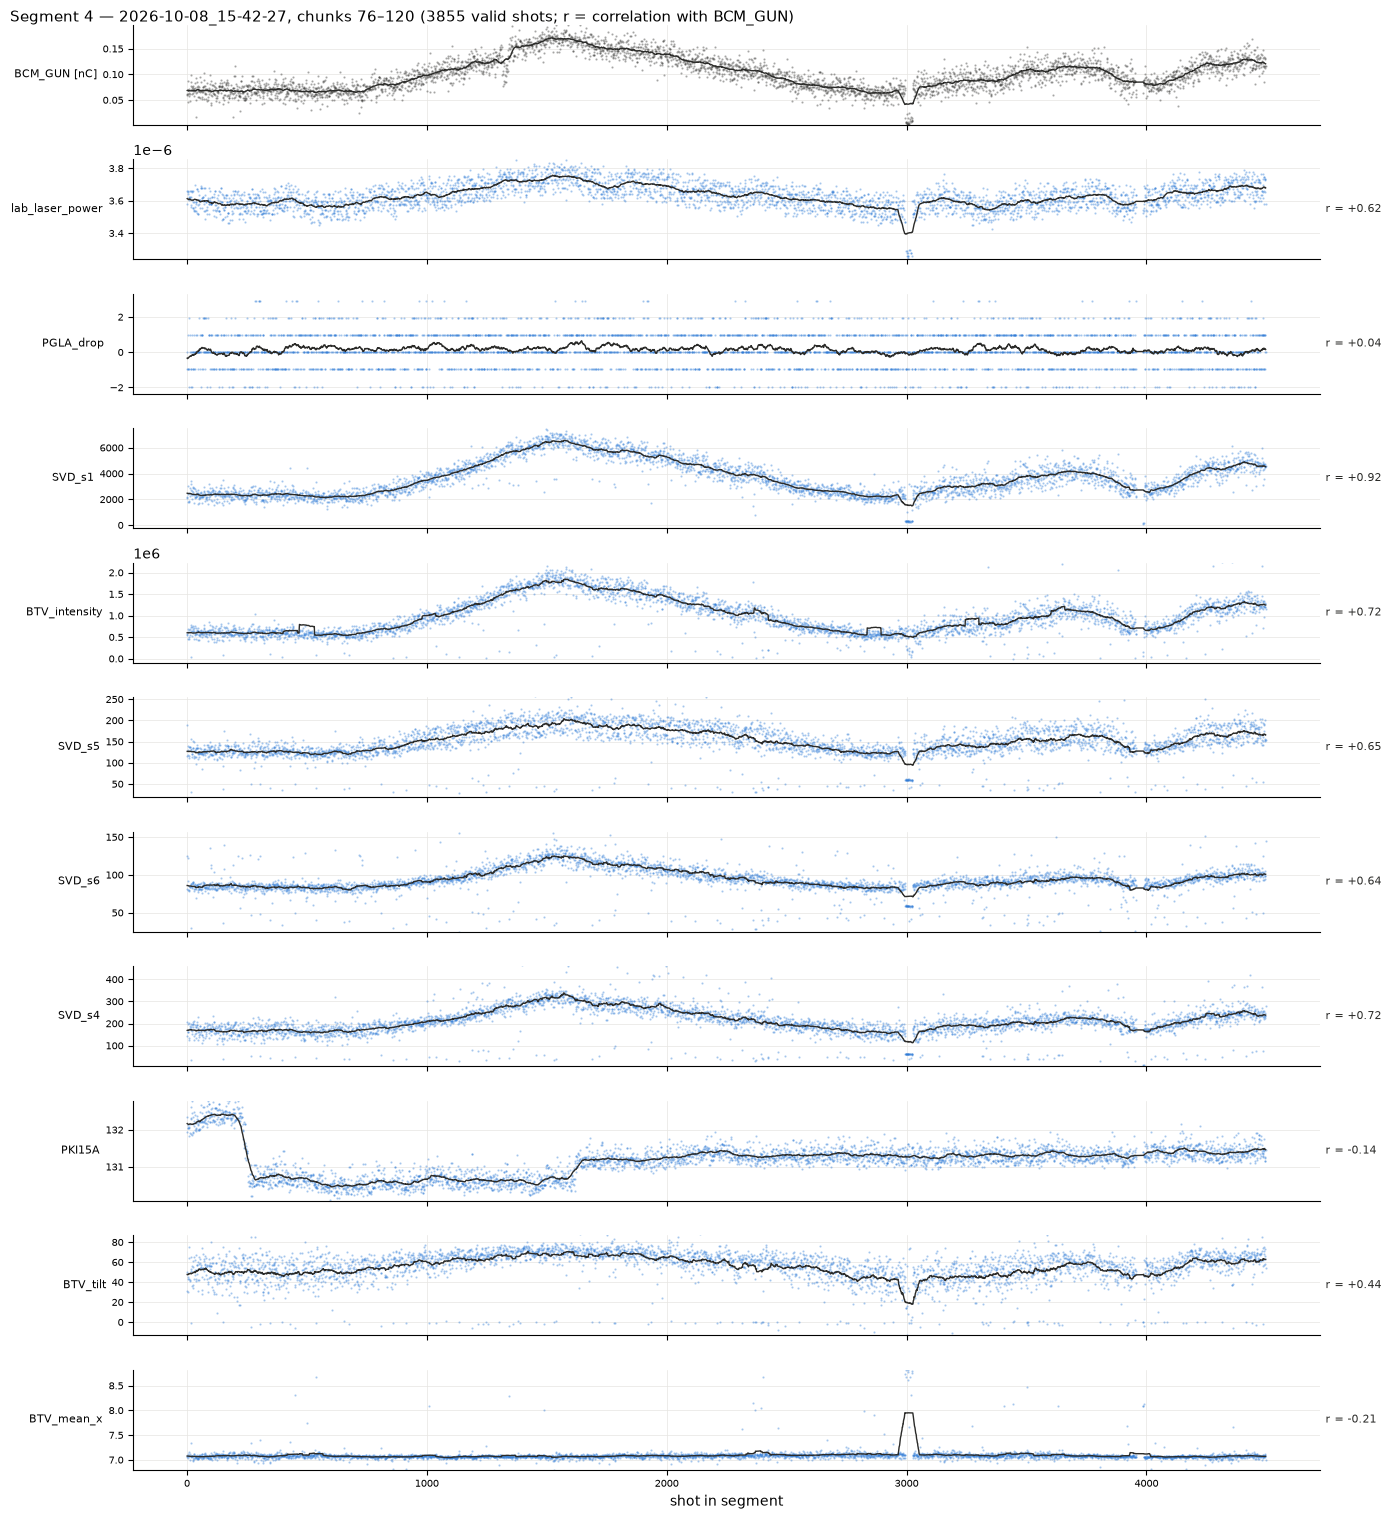

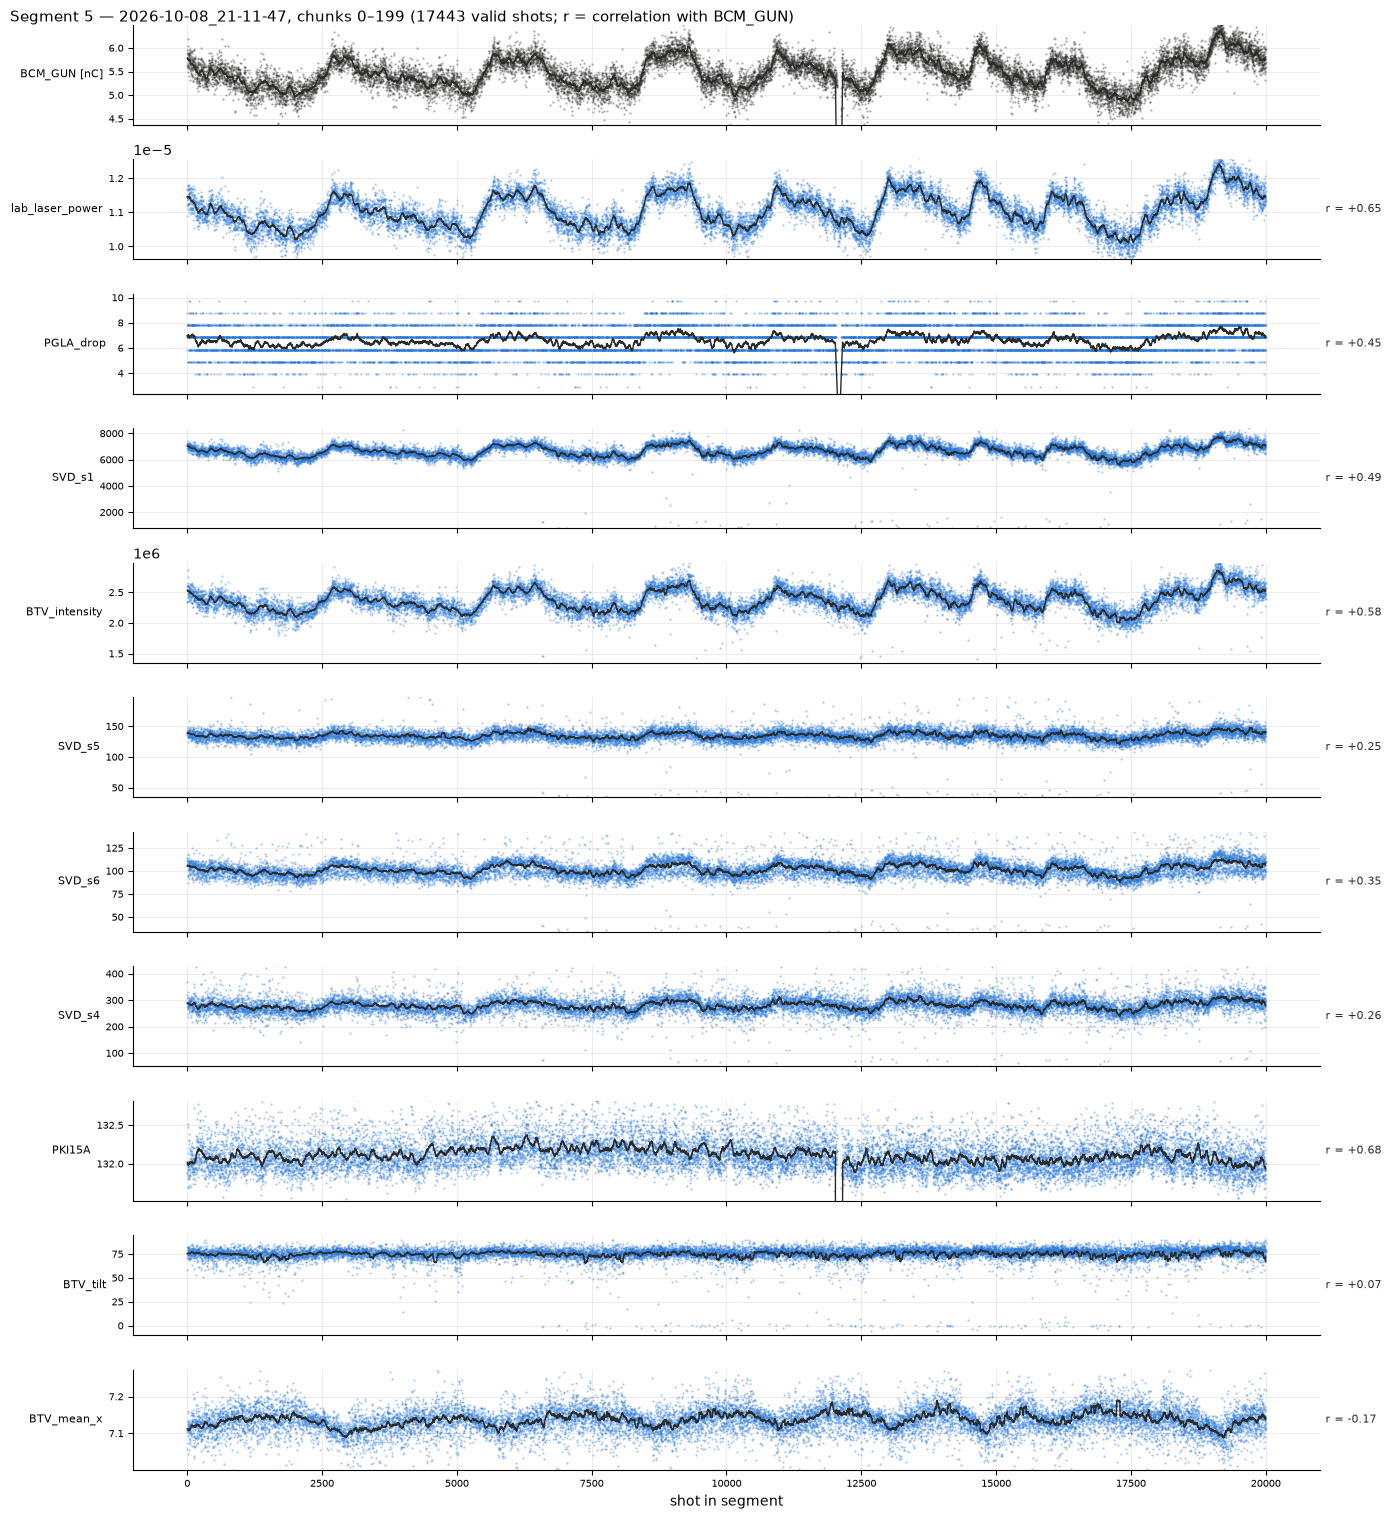

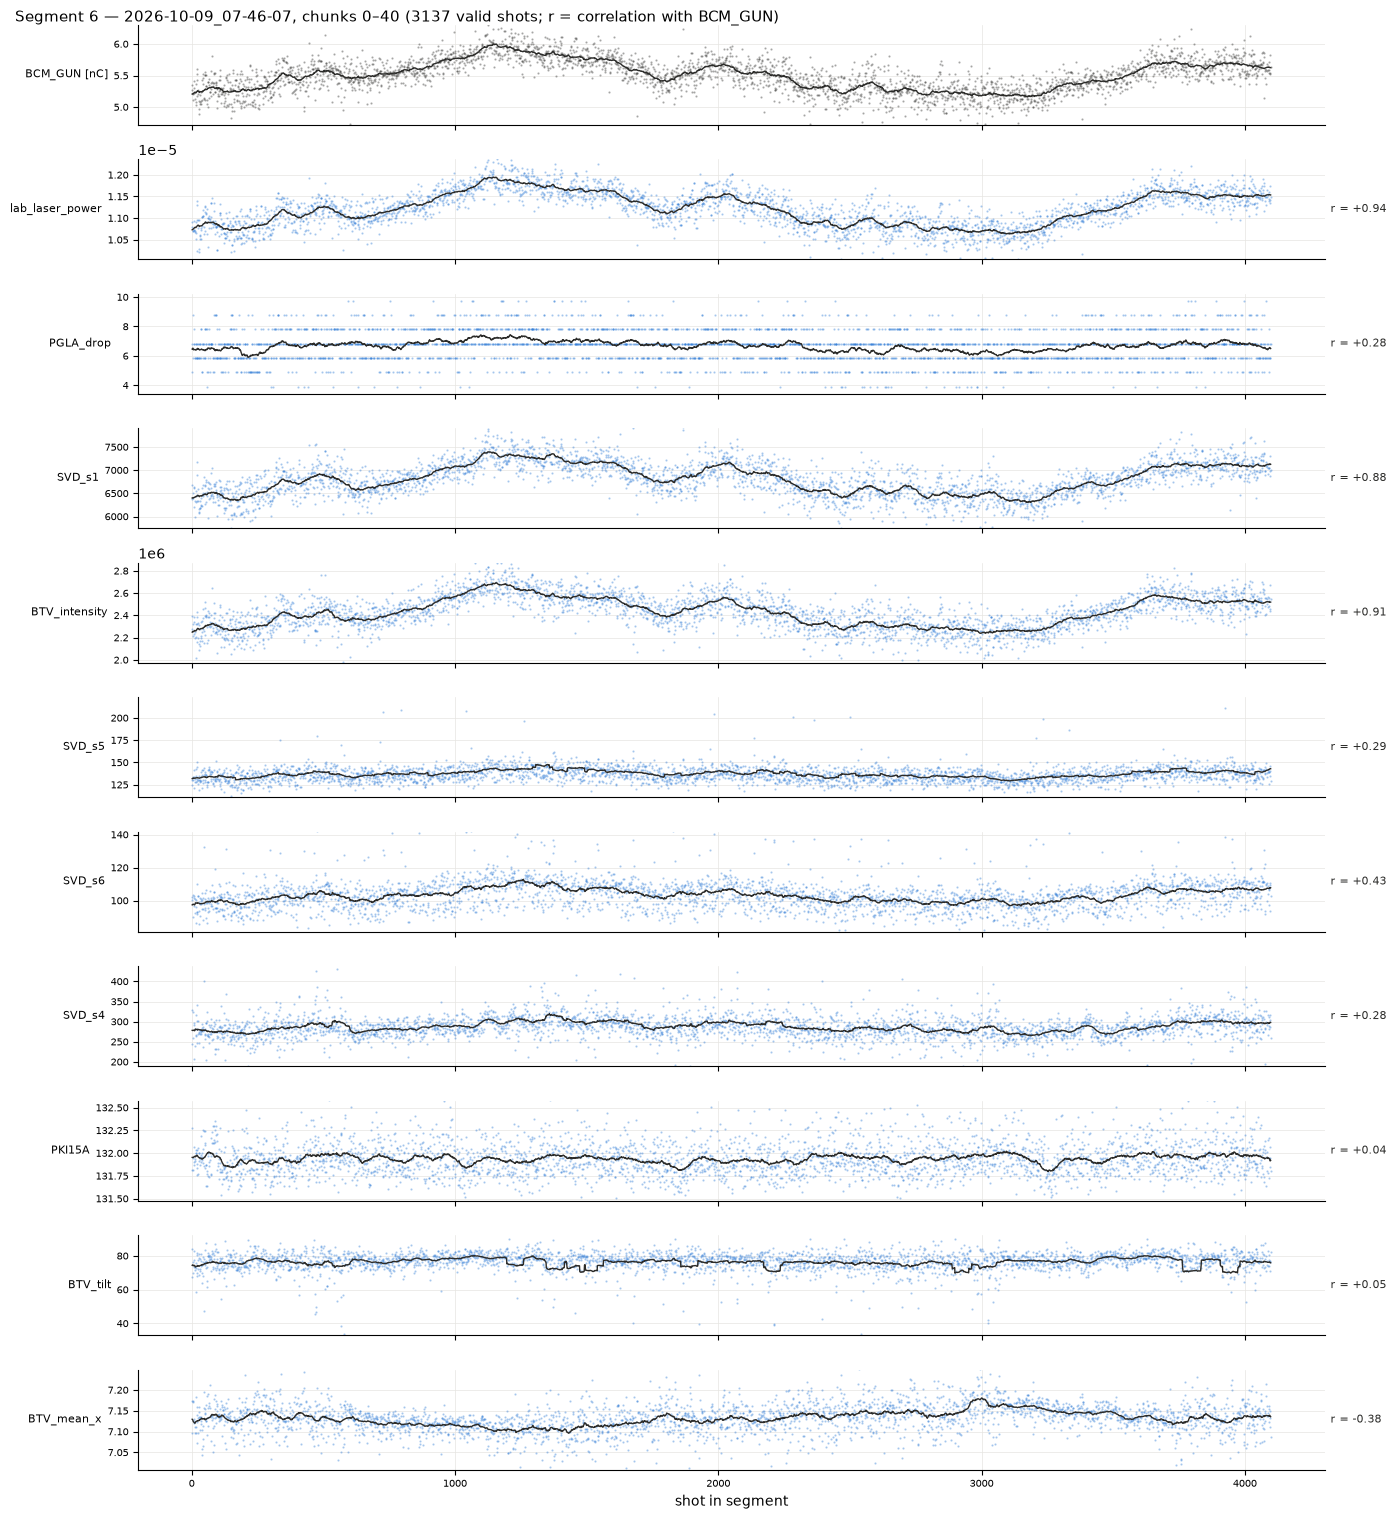

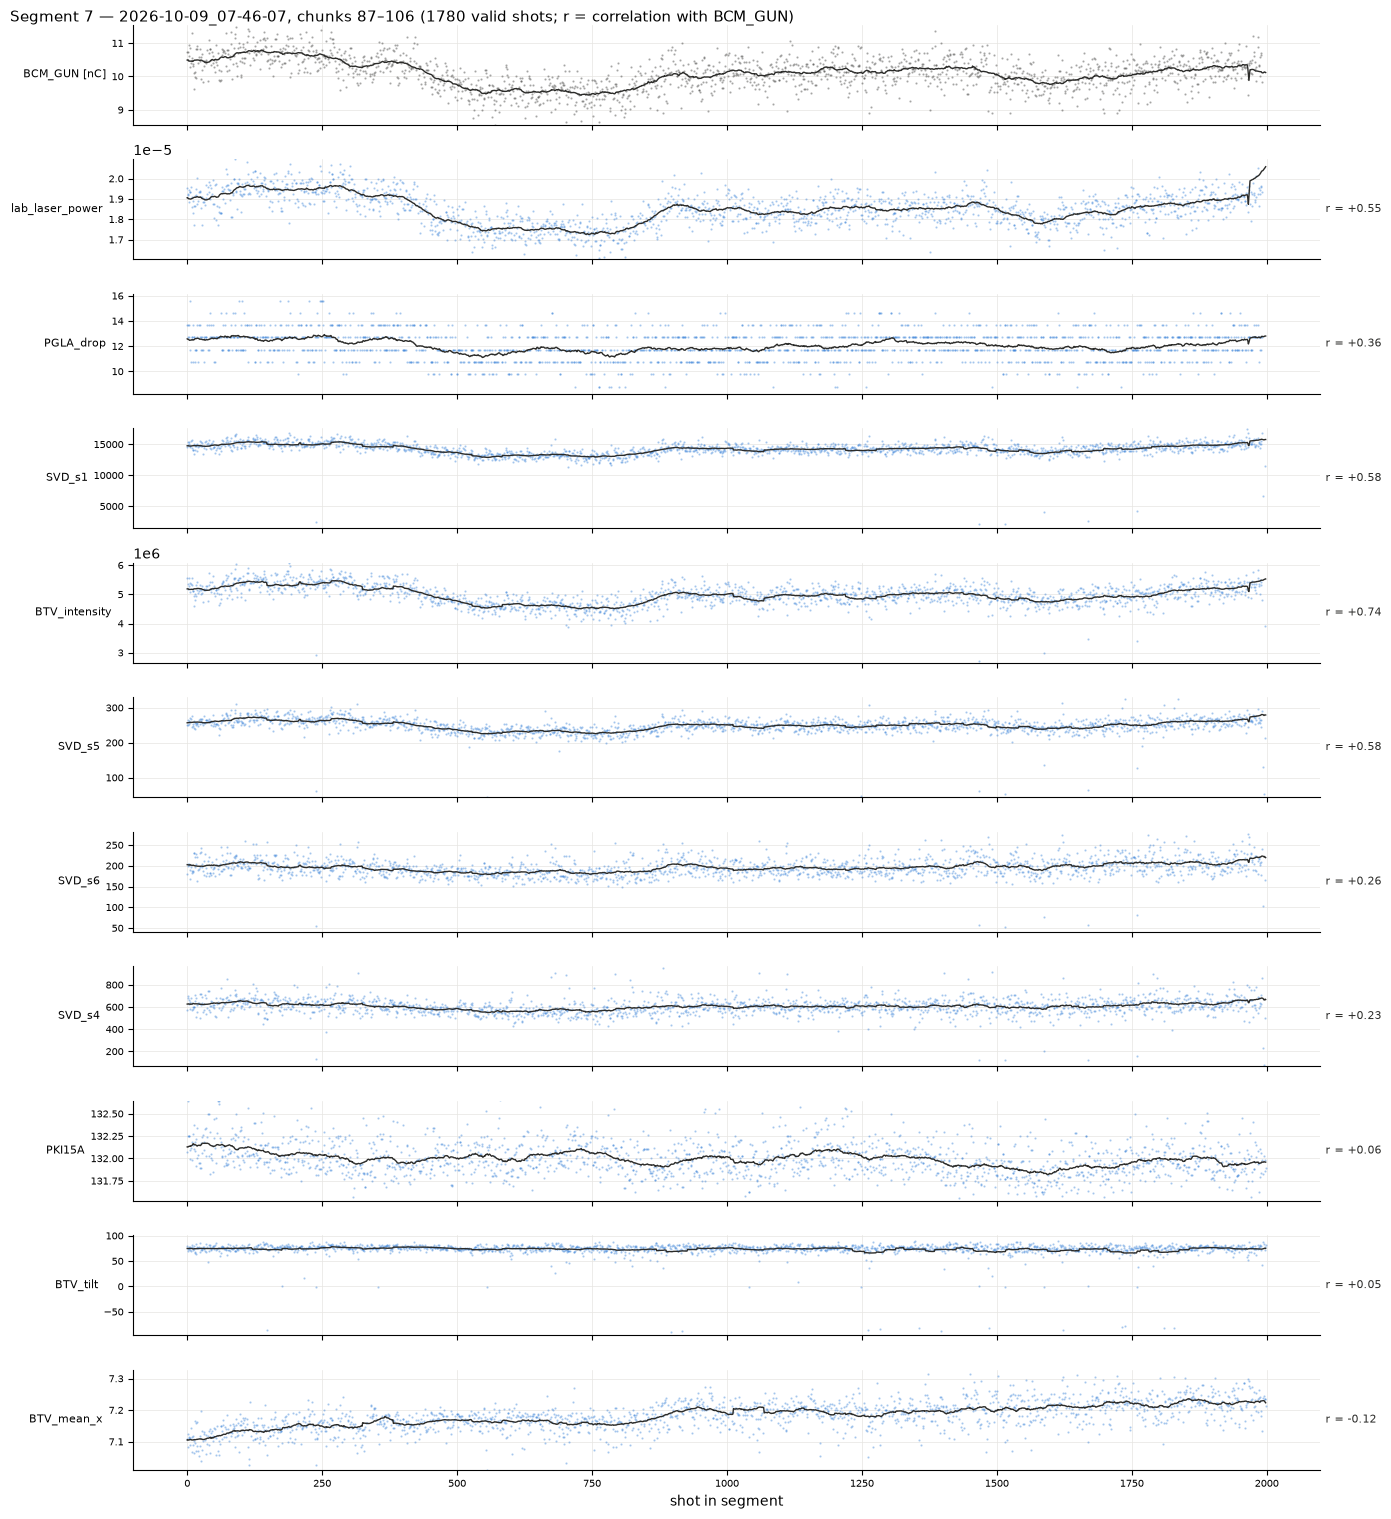

In [4]:
def segment_figure(k, s):
    v = s["valid"]
    shot = np.flatnonzero(v)
    y = s["y"][v]
    rows = [(TARGET + " [nC]", y, BCM_COLOR, None)]
    for f in FEATURES:
        x = s["X"][f].to_numpy()[v]
        ok = ~np.isnan(x)
        r = np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 2 else np.nan
        rows.append((f, x, FEATURE_COLOR, r))

    fig, axes = plt.subplots(len(rows), 1, figsize=(14, 1.35 * len(rows) + 0.6), sharex=True)
    for ax, (name, values, color, r) in zip(axes, rows):
        ax.plot(shot, values, ".", ms=1.2, color=color, alpha=0.35)
        ax.plot(shot, pd.Series(values).rolling(ROLL, center=True, min_periods=1).mean(), color=INK, lw=1)
        lo, hi = np.nanpercentile(values, [0.5, 99.5])
        pad = 0.08 * (hi - lo) if hi > lo else 1
        ax.set_ylim(lo - pad, hi + pad)
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
        ax.tick_params(labelsize=7)
        if r is not None:
            ax.text(1.005, 0.5, f"r = {r:+.2f}", transform=ax.transAxes, va="center", fontsize=8, color=INK)
        ax.grid(color=GRID, lw=0.5)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    axes[-1].set_xlabel("shot in segment")
    fig.suptitle(f"Segment {k} — {s['run'].removeprefix('acquisition_')}, chunks {s['chunks']} "
                 f"({v.sum()} valid shots; r = correlation with {TARGET})", fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(OUT / f"segment_{k:02d}.png", dpi=110, bbox_inches="tight")
    plt.show()


for k, s in segments.items():
    segment_figure(k, s)

## Correlation of every feature with the BCM, all segments

In [5]:
corr = pd.DataFrame({
    k: {f: s["X"].loc[s["valid"], f].corr(pd.Series(s["y"][s["valid"]], index=s["X"].index[s["valid"]])) for f in FEATURES}
    for k, s in segments.items()
}).rename_axis(index="feature", columns="segment")
corr.style.format("{:+.2f}").background_gradient(cmap="RdBu_r", vmin=-1, vmax=1)

segment,0,1,2,3,4,5,6,7
feature,,,,,,,,
lab_laser_power,+0.54,+0.74,+0.23,+0.44,+0.62,+0.65,+0.94,+0.55
PGLA_drop,+0.02,+0.40,-0.09,+0.02,+0.04,+0.45,+0.28,+0.36
SVD_s1,+0.83,+0.41,+0.40,+0.80,+0.92,+0.49,+0.88,+0.58
BTV_intensity,+0.49,+0.44,+0.47,+0.72,+0.72,+0.58,+0.91,+0.74
SVD_s5,+0.38,+0.30,-0.03,+0.37,+0.65,+0.25,+0.29,+0.58
SVD_s6,+0.24,+0.25,+0.20,+0.53,+0.64,+0.35,+0.43,+0.26
SVD_s4,+0.24,+0.21,+0.03,+0.55,+0.72,+0.26,+0.28,+0.23
PKI15A,-0.10,-0.01,+0.10,-0.09,-0.14,+0.68,+0.04,+0.06
BTV_tilt,+0.08,+0.08,-0.02,+0.25,+0.44,+0.07,+0.05,+0.05
